# 03 · A fixed-weight comparison and its actual-minus-synthetic gap

**Synthetic illustration — Not empirical research results**

A weighted donor series offers a transparent comparison path, but a visually
close fit does not by itself establish a valid causal counterfactual. This
notebook uses invented weights and explicitly constructed donor/target paths.

**Learn to:** evaluate a fixed objective, construct the donor combination,
interpret the gap sign and preserve missing-donor rules. We never optimize
weights or read the research's frozen weight files. See [methodology](../docs/methodology.md).


In [1]:
import numpy as np
import pandas as pd
# Keep table outputs plain text for the public safety profile.
pd.set_option("display.notebook_repr_html", False)
import matplotlib.pyplot as plt
from IPython.display import display

LABEL = "Synthetic illustration — Not empirical research results"
plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 12,
                     "axes.labelsize": 10, "font.size": 10})
DEMO_LABEL = "SYNTHETIC DATA — NOT EMPIRICAL RESEARCH RESULTS"
print(DEMO_LABEL)
print(LABEL)


SYNTHETIC DATA — NOT EMPIRICAL RESEARCH RESULTS
Synthetic illustration — Not empirical research results


## 1. Construct the artificial donor experiment

The two teaching weights are **GR = 0.25 and AT = 0.75**. They are not the formal
GY050 weights. The target is deliberately generated from those donors plus an
offset, seeded noise and an invented post-cutoff change. This makes the gap
interpretable without borrowing an empirical trajectory.


In [2]:
from cbam_power._demo import artificial_native, artificial_weather
from cbam_power.market import integrate_native
from cbam_power.panel import assemble_panel
from cbam_power.synthetic import construct_paths, fixed_weight_objective

native_times, fixture = artificial_native()
cutoff = pd.Timestamp("2025-12-31T23:00Z")
midpoint = native_times.floor("h") + pd.Timedelta(minutes=30)
r = np.asarray((midpoint-cutoff).total_seconds()/86400)
post = np.asarray(native_times.floor("h") >= cutoff, dtype=float)
common = fixture - 4*post + .2*post*r  # Remove the fixture's invented policy component from donors.
daily = np.sin(2*np.pi*np.arange(len(native_times))/(24*4))
donor_at = common + 12 + 2*daily
donor_gr = common - 8 - daily
rng = np.random.default_rng(73022)
noise = np.repeat(rng.normal(0., 1.5, len(native_times)//4), 4)
target_me = .75*donor_at + .25*donor_gr + 3 + 8*post + noise
native_by_corridor = {"AT_IT": donor_at, "GR_IT": donor_gr, "ME_IT": target_me,
                      "CH_IT": common + 5, "SI_IT": common + 2}
blocks = []
for corridor, values in native_by_corridor.items():
    block = integrate_native(native_times, values, 15, "commercial_net_MW").reset_index()
    block = block[["timestamp_utc", "commercial_net_MW"]]
    blocks.append(block.assign(corridor_id=corridor,
        physical_net_MW=block.commercial_net_MW*.95,
        origin_price=60., destination_price=70., spread_center=10.))
weather = artificial_weather(pd.DatetimeIndex(native_times.floor("h").unique()))
panel = assemble_panel(pd.concat(blocks, ignore_index=True), weather)
weights = {"DEMO_FIXED": {"GR_IT": .25, "AT_IT": .75}}
paths = construct_paths(panel, weights)
assert paths.weight_version.eq("DEMO_FIXED").all()
assert np.allclose(paths.G_ME, paths.actual_ME-paths.scheduled_export_proxy)
print("Fixed artificial weights:", weights["DEMO_FIXED"], "| optimizer calls: zero")


Fixed artificial weights: {'GR_IT': 0.25, 'AT_IT': 0.75} | optimizer calls: zero


## 2. Evaluate an objective without learning new weights

The formal approach combines standardized energy-mix discrepancies with
outcome-feature blocks. Its composite objective averages rows within blocks
and gives outcome blocks equal shares. Schematically,
$J(w)=\lambda D_{energy}(w)+(1-\lambda)\operatorname{mean}_b D_b(w)$.

The following are already-scaled, invented feature triples in target/GR/AT
order. Calling the package evaluator checks a supplied vector; it does not
choose a vector. The real feature freeze, validation and 16 versions are
separately protected research inputs.


In [3]:
toy_features = [
    ("demo_generation", "energy", np.array([.60, .40, .80])),
    ("demo_monthly", "monthly_path", np.array([.20, -.10, .30])),
    ("demo_hourly", "hour_shape", np.array([-.20, -.40, -.10])),
]
objective, details = fixed_weight_objective(toy_features, [.25, .75], .5)
display(pd.DataFrame(details))
print("Objective at the supplied artificial vector:", round(objective, 6))
assert np.isclose(objective, sum(row["weighted_squared_discrepancy"] for row in details))


           feature         block  objective_row_weight  \
0  demo_generation        energy                  0.50   
1     demo_monthly  monthly_path                  0.25   
2      demo_hourly    hour_shape                  0.25   

   weighted_squared_discrepancy  
0                  5.000000e-03  
1                  1.925930e-34  
2                  1.562500e-04  

Objective at the supplied artificial vector: 0.005156


### Diagnose error and support without refitting the donor weights

The package computes $RMSE=\sqrt{n^{-1}\sum_t(\widehat Y_t-Y_t)^2}$,
$MAE=\operatorname{mean}|\widehat Y-Y|$ and **bias = prediction minus actual**.
The plotted gap has the opposite sign. We report pre/post periods separately
using one fixed vector, and normalize RMSE by the pre-period target standard
deviation. No metric is used to choose new weights or delete observations.

A convex comparison must lie between its two donors at each complete hour.
The target need not lie in that interval: an outside-target share diagnoses
limited support, not a reason to clip the target or extrapolate the weights.


In [4]:
from cbam_power.synthetic import metrics

donor_wide = panel[panel.corridor_id.isin(["GR_IT", "AT_IT"])].pivot(
    index="timestamp_utc", columns="corridor_id", values="scheduled_export_proxy").sort_index()
assert donor_wide.index.equals(pd.DatetimeIndex(paths.timestamp_utc))
lower_support = donor_wide.min(axis=1).to_numpy()
upper_support = donor_wide.max(axis=1).to_numpy()
assert np.all(paths.scheduled_export_proxy.to_numpy() >= lower_support-1e-12)
assert np.all(paths.scheduled_export_proxy.to_numpy() <= upper_support+1e-12)
target_outside = ((paths.actual_ME.to_numpy() < lower_support) |
                  (paths.actual_ME.to_numpy() > upper_support))
before = paths.timestamp_utc.lt(cutoff).to_numpy()
training_sd = float(paths.loc[before, "actual_ME"].std(ddof=1))
diagnostic_rows = []
for period, selected in [("Artificial pre-cutoff", before), ("Artificial post-cutoff", ~before)]:
    chosen = paths.loc[selected]
    measured = metrics(chosen.actual_ME, chosen.scheduled_export_proxy, training_sd)
    diagnostic_rows.append({"period": period, "hours": int(measured["n"]),
        "RMSE_MW": measured["rmse"], "MAE_MW": measured["mae"],
        "NRMSE_pre_target_sd": measured["nrmse"],
        "prediction_minus_actual_bias_MW": measured["bias"],
        "actual_minus_synthetic_mean_MW": float(chosen.G_ME.mean()),
        "target_outside_donor_share": float(target_outside[selected].mean())})
    assert np.isclose(measured["bias"] + chosen.G_ME.mean(), 0., atol=1e-12, rtol=0)
diagnostic_table = pd.DataFrame(diagnostic_rows)
display(diagnostic_table.round(4))
display(pd.DataFrame({"donor": ["GR_IT", "AT_IT"], "artificial_fixed_weight": [.25, .75]}))


                   period  hours  RMSE_MW   MAE_MW  NRMSE_pre_target_sd  \
0   Artificial pre-cutoff    240   3.4073   3.0816               1.3099   
1  Artificial post-cutoff    240  11.0918  10.9974               4.2640   

   prediction_minus_actual_bias_MW  actual_minus_synthetic_mean_MW  \
0                          -3.0606                          3.0606   
1                         -10.9974                         10.9974   

   target_outside_donor_share  
0                       0.125  
1                       1.000  

   donor  artificial_fixed_weight
0  GR_IT                     0.25
1  AT_IT                     0.75

## 3. Read the gap with its explicit sign

$$\widehat Y_{ME,t}=\sum_jw_j\max(NetFlow_{j,t},0),
  \qquad G_{ME,t}=Actual_{ME,t}-\widehat Y_{ME,t}.$$

A positive gap means target exports exceed the fixed donor combination.
Prediction error in some validation tables uses the opposite sign; labels
must distinguish them. The lower panel below plots **actual minus synthetic**.


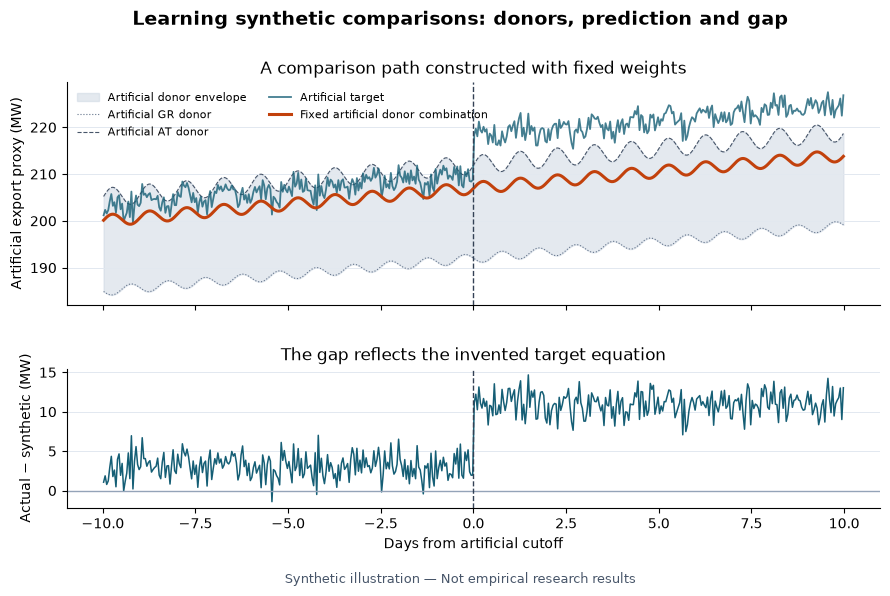

In [5]:
r_days = np.asarray((paths.timestamp_utc + pd.Timedelta(minutes=30)-cutoff).dt.total_seconds()/86400)
figure, axes = plt.subplots(2, 1, figsize=(10.5, 6), sharex=True,
                           gridspec_kw={"height_ratios": [1.6, 1]})
axes[0].fill_between(r_days, lower_support, upper_support, color="#cbd5e1", alpha=.5,
                     label="Artificial donor envelope")
axes[0].plot(r_days, donor_wide["GR_IT"], color="#64748b", linewidth=.8, linestyle=":", label="Artificial GR donor")
axes[0].plot(r_days, donor_wide["AT_IT"], color="#475569", linewidth=.8, linestyle="--", label="Artificial AT donor")
axes[0].plot(r_days, paths.actual_ME, color="#155e75", linewidth=1.3, alpha=.8,
             label="Artificial target")
axes[0].plot(r_days, paths.scheduled_export_proxy, color="#c2410c", linewidth=2.2,
             label="Fixed artificial donor combination")
axes[0].set(ylabel="Artificial export proxy (MW)", title="A comparison path constructed with fixed weights")
axes[0].legend(frameon=False, fontsize=8, ncol=2)
axes[1].plot(r_days, paths.G_ME, color="#155e75", linewidth=1.1)
axes[1].axhline(0, color="#94a3b8", linewidth=1)
axes[1].set(xlabel="Days from artificial cutoff", ylabel="Actual − synthetic (MW)",
            title="The gap reflects the invented target equation")
for axis in axes:
    axis.axvline(0, color="#334155", linestyle="--", linewidth=1)
    axis.grid(axis="y", color="#e2e8f0", linewidth=.7)
figure.suptitle("Learning synthetic comparisons: donors, prediction and gap", fontsize=14, fontweight="bold")
figure.text(.5, .025, LABEL, ha="center", fontsize=9, color="#475569")
figure.subplots_adjust(bottom=.15, top=.86, hspace=.35)
plt.show()


In [6]:
import os
from pathlib import Path

output_root = os.environ.get("CBAM_TEACHING_OUTPUT_ROOT")
if output_root:
    destination = Path(output_root).expanduser().resolve()
    # Explicit exports belong outside the source checkout. The teaching runner
    # additionally confines all writes to its private output root.
    for ancestor in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (ancestor / "pyproject.toml").is_file() and (ancestor / "src/cbam_power").is_dir():
            if destination.is_relative_to(ancestor) or ancestor.is_relative_to(destination):
                raise ValueError("TEACHING_OUTPUT_MUST_BE_OUTSIDE_CHECKOUT")
    destination.mkdir(parents=True, exist_ok=True)
    target = destination / "synthetic_demo.png"
    if target.exists():
        raise FileExistsError("TEACHING_FIGURE_ALREADY_EXISTS")
    figure.savefig(target, dpi=180, facecolor="white", metadata={"Software": "Matplotlib"})
    print("Created synthetic_demo.png from this artificial notebook.")


## 4. Missing donors and positive parts are substantive rules

If one donor is missing, the package preserves a missing synthetic hour; it
does not renormalize the remaining weight to one. A separate one-hour example
makes the positive-before-weighting rule visible. Neither check changes the
intact series used in the figure.


In [7]:
first_hour = panel.timestamp_utc.min()
incomplete = panel.copy()
affected = incomplete.timestamp_utc.eq(first_hour) & incomplete.corridor_id.eq("GR_IT")
incomplete.loc[affected, ["scheduled_export_proxy", "commercial_net_MW"]] = np.nan
missing_paths = construct_paths(incomplete, weights)
assert pd.isna(missing_paths.loc[missing_paths.timestamp_utc.eq(first_hour),
                                "scheduled_export_proxy"]).all()

example = panel[panel.timestamp_utc.eq(first_hour)].copy()
for corridor, value in [("AT_IT", -20.), ("GR_IT", 40.)]:
    selected = example.corridor_id.eq(corridor)
    example.loc[selected, "commercial_net_MW"] = value
    example.loc[selected, "scheduled_export_proxy"] = max(value, 0)
positive_first = construct_paths(example, weights).scheduled_export_proxy.iloc[0]
assert positive_first == 10.
print("Positive before weighting:", positive_first, "MW; the reversed order would give 0 MW.")
print("Missing donor → missing synthetic hour; no hourly weight renormalization.")


Positive before weighting: 10.0 MW; the reversed order would give 0 MW.
Missing donor → missing synthetic hour; no hourly weight renormalization.


In this invented example, the post-cutoff target moves farther from the donor
envelope because an 8 MW increment was explicitly inserted into its equation.
That construction explains the visual gap; it is not evidence that CBAM caused
a real change. A missing donor still gives a missing comparison hour, even
when the remaining donor could be used to draw a smooth-looking line.


## Interpretation limits

The demonstration creates a plausible comparator by construction. Genuine
donor support, prefit quality and robustness must be audited separately.
Conditional outcome-regression HAC does not account for every uncertainty in
counterfactual design. The formal workflow retains frozen donors and weights,
no 600 MW clipping, weak-support diagnostics and blocked synthetic branches;
none is remedied by this artificial example.

Continue to [robustness and validation](04_robustness_and_validation.ipynb).
The optional external figure export is reproducible from these cells only.


## Reproducible numerical checkpoints

The following values summarize this artificial run. The teaching runner
compares them across clean-kernel executions; they are not empirical
baselines. All values come from the calculations above, with no private
inputs or fitted research values. Presentation rounding does not change
the unrounded checkpoints.


In [8]:
PUBLIC_NUMERICAL_CHECKPOINTS = {
    "example": "DEMO_FIXED_WEIGHT_SYNTHETIC", "seed": 73022,
    "hours": int(len(paths)), "artificial_GR_weight": .25, "artificial_AT_weight": .75,
    "objective_at_fixed_weights": float(objective),
    "pre_RMSE_MW": float(diagnostic_rows[0]["RMSE_MW"]),
    "post_RMSE_MW": float(diagnostic_rows[1]["RMSE_MW"]),
    "pre_MAE_MW": float(diagnostic_rows[0]["MAE_MW"]),
    "post_MAE_MW": float(diagnostic_rows[1]["MAE_MW"]),
    "pre_NRMSE": float(diagnostic_rows[0]["NRMSE_pre_target_sd"]),
    "post_NRMSE": float(diagnostic_rows[1]["NRMSE_pre_target_sd"]),
    "pre_prediction_minus_actual_bias_MW": float(diagnostic_rows[0]["prediction_minus_actual_bias_MW"]),
    "post_prediction_minus_actual_bias_MW": float(diagnostic_rows[1]["prediction_minus_actual_bias_MW"]),
    "pre_actual_minus_synthetic_gap_MW": float(diagnostic_rows[0]["actual_minus_synthetic_mean_MW"]),
    "post_actual_minus_synthetic_gap_MW": float(diagnostic_rows[1]["actual_minus_synthetic_mean_MW"]),
    "pre_target_outside_donor_share": float(diagnostic_rows[0]["target_outside_donor_share"]),
    "post_target_outside_donor_share": float(diagnostic_rows[1]["target_outside_donor_share"]),
    "missing_donor_hours_preserved": int(missing_paths.scheduled_export_proxy.isna().sum()),
    "positive_before_weighting_MW": float(positive_first),
    "gap_identity_max_error": float(np.max(np.abs(paths.G_ME-paths.actual_ME+paths.scheduled_export_proxy)))}


import json
json.dumps(PUBLIC_NUMERICAL_CHECKPOINTS, allow_nan=False, sort_keys=True)
display(pd.DataFrame({"checkpoint": list(PUBLIC_NUMERICAL_CHECKPOINTS),
                      "value": list(PUBLIC_NUMERICAL_CHECKPOINTS.values())}))


                              checkpoint                        value
0                                example  DEMO_FIXED_WEIGHT_SYNTHETIC
1                                   seed                        73022
2                                  hours                          480
3                   artificial_GR_weight                         0.25
4                   artificial_AT_weight                         0.75
5             objective_at_fixed_weights                     0.005156
6                            pre_RMSE_MW                     3.407338
7                           post_RMSE_MW                    11.091802
8                             pre_MAE_MW                     3.081572
9                            post_MAE_MW                    10.997387
10                             pre_NRMSE                      1.30988
11                            post_NRMSE                     4.264012
12   pre_prediction_minus_actual_bias_MW                    -3.060573
13  post_prediction_